# WP10 — Gerçek dört kollu molekül/protein GNN eğitimi

Kullanıcı gerçek eğitimi onayladı. **A0P0/A0P1/A1P0/A1P1**, aynı150 boyutlu mimari, aynı context başlangıçları ve frozen train-only kaynaklarla eğitildi. Shuffled PPI deneyleri eklenmedi. Bu notebook modelleri yeniden eğitmez; gerçek kayıtlı fit/OOF/NPZ dosyalarını okur.

Görev SIDER'da **gözlenen kayıtları sıralamak**. Unknown çiftler doğrulanmış biyolojik negatif değildir. Sigmoidler klinik yan etki olasılığı,kalibrasyon veya nedensellik kanıtı değildir. Önceki baseline/WP09 sonuçları görüldüğünden çalışma keşifseldir.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from wp10_train import QA,MODEL,NAMES,restore,torch
from wp10_molecular_graph import load_store
torch.set_num_threads(1)
FIG=ROOT/'reports/figures/WP10/training_v1';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',180);pd.set_option('display.max_columns',22)
fit=pd.read_csv(QA/'model_fit_summary.csv');metrics=pd.read_csv(QA/'metrics_with_group_CI.csv')
effects=pd.read_csv(QA/'factorial_contrasts_group_CI.csv');coverage=pd.read_csv(QA/'evaluation_coverage.csv')
run=json.loads((QA/'run_config.json').read_text(encoding='utf-8'));done=json.loads((QA/'training_complete.json').read_text(encoding='utf-8'))
display(pd.DataFrame([done]).drop(columns=['semantics']));display(pd.read_csv(QA/'excluded_inner_jobs.csv'))

,version,jobs_recorded,optimizer_steps,fit_status_counts,outer_complete_count,source_positives,source_drugs,source_PT,outer_test_scores_produced,prior_files_verified
0,WP10-molecular-protein-factorial-observed-reco...,152,8611,{'OK': 152},10,6416,62,1061,False,2487


,context,protocol,outer_fold,inner_fold,model,status,reason,optimizer_steps,prediction_produced
0,primary_o02_i01,primary,2,1,A0P0,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
1,primary_o02_i01,primary,2,1,A0P1,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
2,primary_o02_i01,primary,2,1,A1P0,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
3,primary_o02_i01,primary,2,1,A1P1,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
4,stress_o02_i02,stress,2,2,A0P0,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
5,stress_o02_i02,stress,2,2,A0P1,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
6,stress_o02_i02,stress,2,2,A1P0,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False
7,stress_o02_i02,stress,2,2,A1P1,SKIPPED_FROZEN_COMMON_SCOPE,existing accepted shared-inner policy;NO new s...,0,False


**Yorum:**112 inner ve40 outer olmak üzere152 fit kaydedildi. Önceden dışlanan iki inner bağlam dört varyant için de dışarıda:8 iş eğitilmedi. Bu seçim düşük sonuç nedeniyle yapılmadı;eski ortak inner sözleşmesi korunur.62 ilaç envanterde,54 atom maskesi açık ve8 QC kapalıdır. Methenamine için tüm kişiselleştirilmiş girdi eksikliği korunur.

## 1. Gerçek eğitim eğrileri

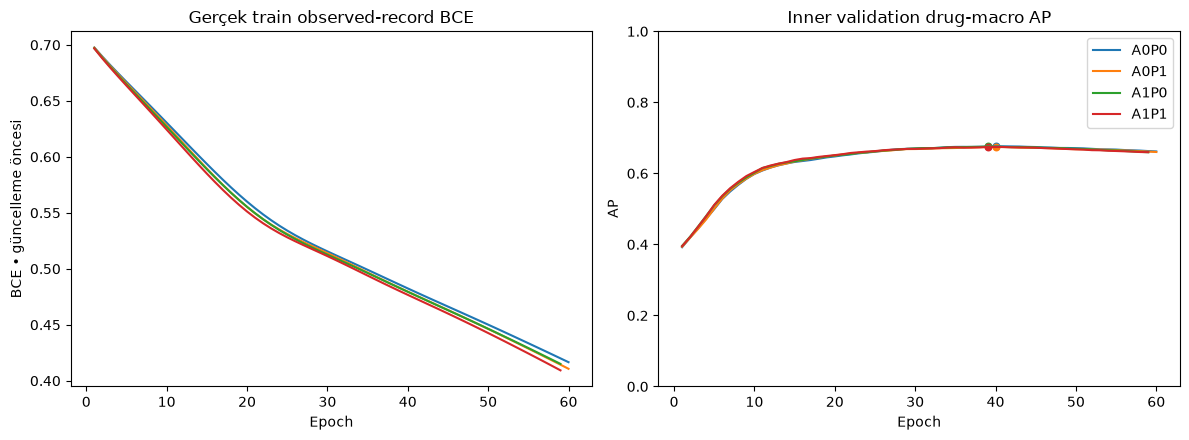

,model,epochs_run,best_epoch,best_validation_AP,optimizer_steps
0,A0P0,60,40,0.676603,60
1,A0P1,60,40,0.675236,60
2,A1P0,59,39,0.675860,59
3,A1P1,59,39,0.674243,59


In [2]:
first=fit[fit.context.eq('primary_o01_i01')]
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for name in NAMES:
    row=first[first.model.eq(name)].iloc[0];history=pd.read_csv(QA/'history'/(row.job_key+'.csv'))
    axs[0].plot(history.epoch,history.train_BCE_pre_update,label=name)
    axs[1].plot(history.epoch,history.validation_drug_AP,label=name)
    best=history[history.epoch.eq(row.best_epoch)].iloc[0];axs[1].scatter([row.best_epoch],[best.validation_drug_AP],s=22)
axs[0].set(title='Gerçek train observed-record BCE',xlabel='Epoch',ylabel='BCE • güncelleme öncesi')
axs[1].set(title='Inner validation drug-macro AP',xlabel='Epoch',ylabel='AP',ylim=(0,1));axs[1].legend()
plt.tight_layout();plt.savefig(FIG/'01_training_curves.png',dpi=160);plt.show()
display(first[['model','epochs_run','best_epoch','best_validation_AP','optimizer_steps']])

**Yorum:**Grafik ilk sıralı inner bağlamı gösterir;152 fitin bütün loss/validation eğrileri history klasöründedir. Yalnız inner validation AP checkpoint seçer,max200/patience20/min_delta0.0001 sabittir. Noktalar seçilmiş epoch'tur. Outer test bu eğrilere girmez;sonuç sonrası süre veya parametre araması yapılmadı.

## 2. Outer epoch ve gerçek öğrenme kanıtı

,protocol,outer_fold,model,best_epoch,num_targets,optimizer_steps,status
12,primary,1,A0P0,40,240,40,OK
13,primary,1,A0P1,40,240,40,OK
14,primary,1,A1P0,39,240,39,OK
15,primary,1,A1P1,39,240,39,OK
24,primary,2,A0P0,39,286,39,OK
25,primary,2,A0P1,39,286,39,OK
26,primary,2,A1P0,44,286,44,OK
27,primary,2,A1P1,39,286,39,OK
40,primary,3,A0P0,40,318,40,OK
41,primary,3,A0P1,42,318,42,OK


,fits,steps,minimum_PPI_max_gradient,minimum_atom_max_gradient,minimum_bond_max_gradient,minimum_weight_change
model,,,,,,
A0P0,38,2174,0.000000,0.000000,0.000000,4.123528
A0P1,38,2134,0.008411,0.000000,0.000000,3.795212
A1P0,38,2186,0.000000,0.000208,0.000757,3.896933
A1P1,38,2117,0.008020,0.000187,0.000705,3.597905


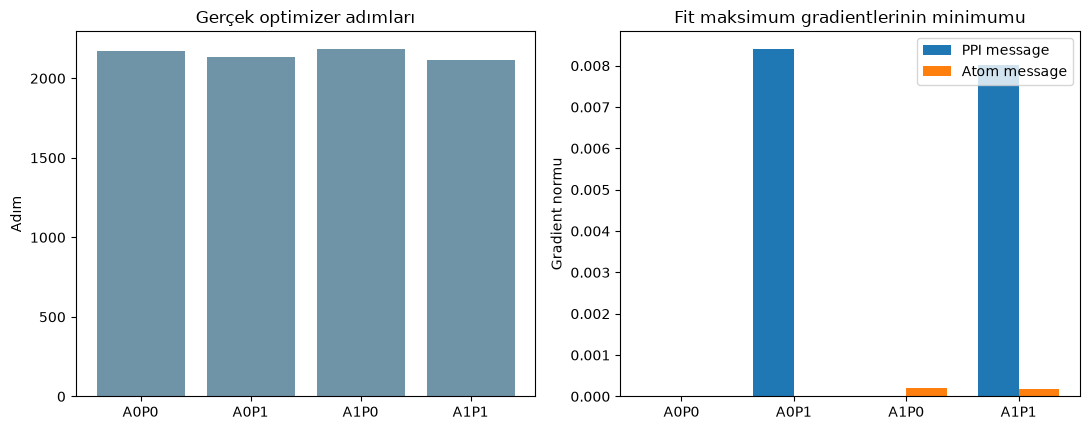

In [3]:
outer=fit[fit.inner_fold.eq(0)];display(outer[['protocol','outer_fold','model','best_epoch','num_targets','optimizer_steps','status']])
proof=fit.groupby('model').agg(fits=('job_key','size'),steps=('optimizer_steps','sum'),minimum_PPI_max_gradient=('maximum_message_gradient_norm','min'),minimum_atom_max_gradient=('maximum_atom_message_gradient_norm','min'),minimum_bond_max_gradient=('maximum_bond_message_gradient_norm','min'),minimum_weight_change=('selected_state_L2_change','min'))
display(proof)
fig,axs=plt.subplots(1,2,figsize=(11,4.4))
axs[0].bar(proof.index,proof.steps,color='#7094a7');axs[0].set(title='Gerçek optimizer adımları',ylabel='Adım')
axs[1].bar(np.arange(4)-.18,proof.minimum_PPI_max_gradient,width=.36,label='PPI message');axs[1].bar(np.arange(4)+.18,proof.minimum_atom_max_gradient,width=.36,label='Atom message')
axs[1].set_xticks(range(4),proof.index);axs[1].set(title='Fit maksimum gradientlerinin minimumu',ylabel='Gradient normu');axs[1].legend()
plt.tight_layout();plt.savefig(FIG/'02_actual_optimizer_gradients.png',dpi=160);plt.show()

**Yorum:**A1 modellerinde atom/bond parametrelerine,A?P1 modellerinde protein komşu mesajına gerçek eğitim gradienti ulaştı. A0 molekül ağırlıkları kullanılmaz ve değişmez;P0 komşu mesajı gerçekten0'dır. P0'da sıfır gradientli ağırlığın AdamW decay ile kayması komşuluk kullanımı kanıtı değildir. Her outer modelin epoch'u aynı ortak inner foldlardaki kendi best-epoch medyanından .5 yukarı seçildi;testle early-stop yoktur.

## 3. Aynı kapsamda dört kol ve sabit referanslar

,protocol,model,estimate,CI95_low,CI95_high
0,primary,B2,0.626239,0.579200,0.670094
6,primary,B1,0.655642,0.613111,0.692041
12,primary,B0_all_train,0.646507,0.603990,0.685192
18,primary,B0_like_B2,0.646604,0.604371,0.685339
24,primary,B0_like_B1,0.643787,0.602130,0.681983
30,primary,WP09_G_noPPI,0.643021,0.598498,0.684101
36,primary,WP09_G_realPPI,0.642880,0.597754,0.684922
42,primary,A0P0,0.642740,0.599338,0.684775
48,primary,A0P1,0.643636,0.600493,0.685583
54,primary,A1P0,0.645930,0.602034,0.686449


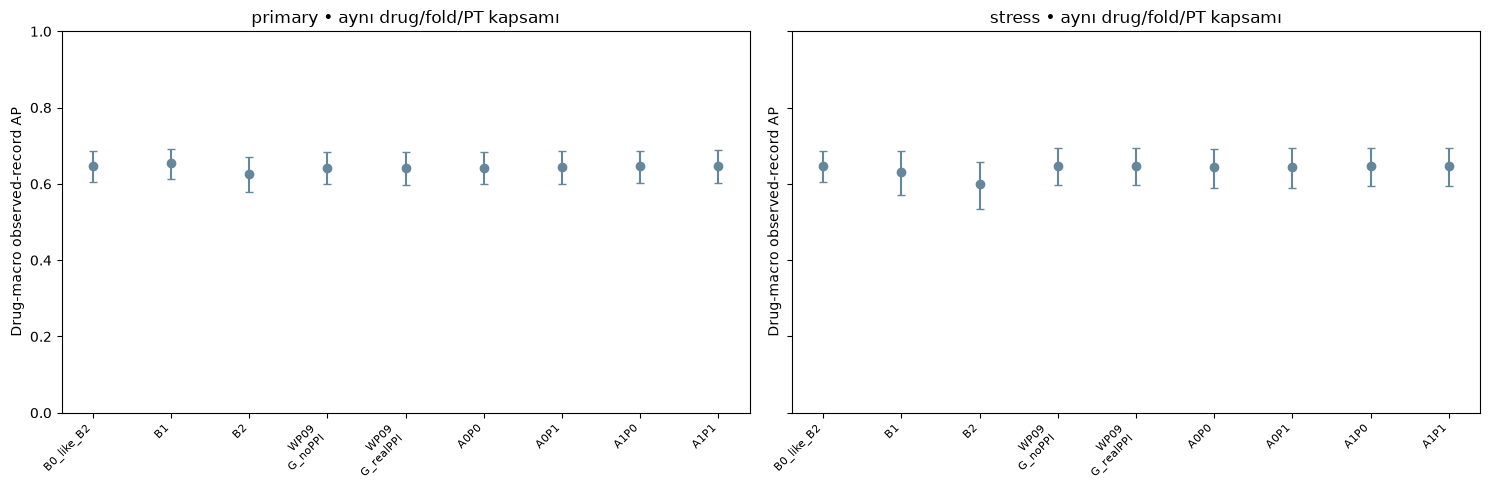

In [4]:
order=['B0_like_B2','B1','B2','WP09_G_noPPI','WP09_G_realPPI']+list(NAMES)
ap=metrics[metrics.scope.eq('paired54')&metrics.metric.eq('drug_macro_AP')]
display(ap[['protocol','model','estimate','CI95_low','CI95_high']])
fig,axs=plt.subplots(1,2,figsize=(15,5),sharey=True)
for ax,protocol in zip(axs,['primary','stress']):
    sub=ap[ap.protocol.eq(protocol)].set_index('model').loc[order]
    ax.errorbar(range(len(order)),sub.estimate,yerr=np.vstack([sub.estimate-sub.CI95_low,sub.CI95_high-sub.estimate]),fmt='o',capsize=3,color='#64879b')
    ax.set_xticks(range(len(order)),[n.replace('WP09_','WP09\n') for n in order],rotation=45,ha='right',fontsize=8)
    ax.set(title=protocol+' • aynı drug/fold/PT kapsamı',ylabel='Drug-macro observed-record AP',ylim=(0,1))
plt.tight_layout();plt.savefig(FIG/'03_shared_AP_references.png',dpi=160);plt.show()

**Yorum:**B0/B1/B2 veWP09 skorları tekrar fit edilmedi;aynı anahtarlarda sabit referans olarak değerlendirildi. Dört yeni kol aynı genişletilmiş mimaridedir. Eski141 boyutluWP09 ile yeni150 boyutluA0 modellerin farkı tek başına atom/PPI etkisi değildir;başlık vebaşlangıç ağırlık şekli de değişir. Doğrudan katkı için aşağıdaki aynı mimarili factorial kontrastlar kullanılır.

## 4. Atom,PPI ve etkileşim

,protocol,contrast,estimate,CI95_low,CI95_high,coefficients
0,primary,atom_P0,0.003189,0.000398,0.006675,"{""A1P0"": 1, ""A0P0"": -1}"
3,primary,atom_P1,0.002598,0.000717,0.004763,"{""A1P1"": 1, ""A0P1"": -1}"
6,primary,PPI_A0,0.000896,-0.001048,0.002651,"{""A0P1"": 1, ""A0P0"": -1}"
9,primary,PPI_A1,0.000305,-0.002156,0.002497,"{""A1P1"": 1, ""A1P0"": -1}"
12,primary,interaction,-0.000591,-0.003102,0.001541,"{""A1P1"": 1, ""A0P1"": -1, ""A1P0"": -1, ""A0P0"": 1}"
15,primary,marginal_atom,0.002894,0.000773,0.005470,"{""A1P0"": 0.5, ""A0P0"": -0.5, ""A1P1"": 0.5, ""A0P1..."
18,primary,marginal_PPI,0.000600,-0.001133,0.002316,"{""A0P1"": 0.5, ""A0P0"": -0.5, ""A1P1"": 0.5, ""A1P0..."
42,stress,atom_P0,0.002730,-0.000045,0.006525,"{""A1P0"": 1, ""A0P0"": -1}"
45,stress,atom_P1,0.002305,-0.000043,0.005478,"{""A1P1"": 1, ""A0P1"": -1}"
48,stress,PPI_A0,0.000497,-0.001052,0.001818,"{""A0P1"": 1, ""A0P0"": -1}"


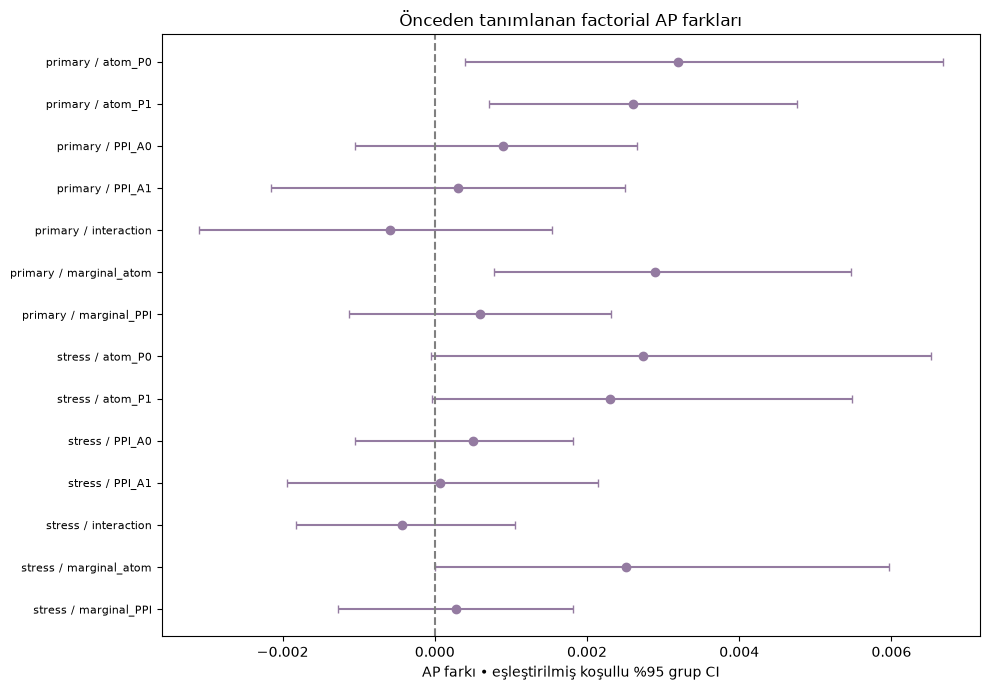

In [5]:
primary_effect=effects[effects.scope.eq('paired54')&effects.metric.eq('drug_macro_AP')]
display(primary_effect[['protocol','contrast','estimate','CI95_low','CI95_high','coefficients']])
fig,ax=plt.subplots(figsize=(10,7));y=np.arange(len(primary_effect))
ax.errorbar(primary_effect.estimate,y,xerr=np.vstack([primary_effect.estimate-primary_effect.CI95_low,primary_effect.CI95_high-primary_effect.estimate]),fmt='o',capsize=3,color='#947ba1')
ax.axvline(0,color='gray',ls='--');ax.set_yticks(y,[r.protocol+' / '+r.contrast for r in primary_effect.itertuples()],fontsize=8);ax.invert_yaxis()
ax.set(title='Önceden tanımlanan factorial AP farkları',xlabel='AP farkı • eşleştirilmiş koşullu %95 grup CI')
plt.tight_layout();plt.savefig(FIG/'04_factorial_contrasts.png',dpi=160);plt.show()

**Yorum:**atom_P0=A1P0−A0P0;atom_P1=A1P1−A0P1;PPI_A0=A0P1−A0P0;PPI_A1=A1P1−A1P0. Etkileşim=(A1P1−A0P1)−(A1P0−A0P0). Marjinal etkiler iki koşullu farkın eşit ortalamasıdır,tahmin ensemble'i değildir. Bunlar biyolojik nedensellik ölçüsü değildir.1000 bootstrap aynı frozen yapısal grupları birlikte veaynı çekimlerle örnekler;CI sabitOOF'ye koşulludur,tam tekrar eğitim veya bağımsız dış doğrulama değildir. Sıfırı içerenCI eşdeğerlik kanıtı sayılmaz.

## 5. Kapsam ve tanımsız metrikler

,protocol,scope,model,semantics,inventory_drugs,scored_drugs,AP_evaluable_drugs,expected_scored_pairs,scored_pairs,excluded_comparison_keys,observed_positive_scored,unknown_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,scored_class_union,class_AUROC_evaluable,class_AUROC_NA
10,primary,paired54,A1P1,Observed SIDER record ranking proxy; unknown N...,62,54,54,13964,13964,0,3820,10144,5505,1685,306,256,50
19,primary,own61,A1P1,Observed SIDER record ranking proxy; unknown N...,62,61,61,18004,18004,0,4576,13428,6405,1829,350,293,57
30,stress,paired54,A1P1,Observed SIDER record ranking proxy; unknown N...,62,54,54,13890,13890,0,3751,10139,5505,1754,307,257,50
39,stress,own61,A1P1,Observed SIDER record ranking proxy; unknown N...,62,61,61,17970,17970,0,4569,13401,6405,1836,351,300,51


,protocol,model,status,ilaç
0,primary,A0P0,ABSTAIN_no_input,1
1,primary,A0P0,SCORED,61
2,primary,A0P1,ABSTAIN_no_input,1
3,primary,A0P1,SCORED,61
4,primary,A1P0,ABSTAIN_no_input,1
5,primary,A1P0,SCORED,61
6,primary,A1P1,ABSTAIN_no_input,1
7,primary,A1P1,SCORED,61
8,stress,A0P0,ABSTAIN_no_input,1
9,stress,A0P0,SCORED,61


,protocol,model,metric,estimate,interpretation
43,primary,A0P0,micro_AP,0.564197,observed-record ranking
46,primary,A0P0,class_macro_AUROC,0.473345,pooled diagnostic only
47,primary,A0P0,within_fold_class_macro_AUROC,0.520670,within-fold descriptive mean
49,primary,A0P1,micro_AP,0.569012,observed-record ranking
52,primary,A0P1,class_macro_AUROC,0.479945,pooled diagnostic only
53,primary,A0P1,within_fold_class_macro_AUROC,0.528122,within-fold descriptive mean
55,primary,A1P0,micro_AP,0.567252,observed-record ranking
58,primary,A1P0,class_macro_AUROC,0.472278,pooled diagnostic only
59,primary,A1P0,within_fold_class_macro_AUROC,0.522878,within-fold descriptive mean
61,primary,A1P1,micro_AP,0.572040,observed-record ranking


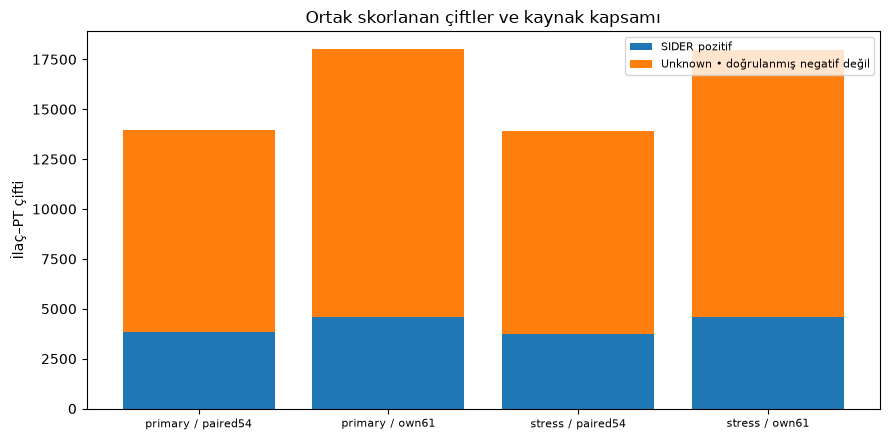

In [6]:
sub=coverage[coverage.model.eq('A1P1')];display(sub)
display(pd.read_csv(QA/'prediction_status_all62.csv').groupby(['protocol','model','status']).size().rename('ilaç').reset_index())
secondary=metrics[metrics.model.isin(NAMES)&metrics.scope.eq('paired54')&metrics.metric.isin(['micro_AP','within_fold_class_macro_AUROC','class_macro_AUROC'])]
display(secondary[['protocol','model','metric','estimate','interpretation']])
fig,ax=plt.subplots(figsize=(9,4.5));xx=np.arange(len(sub))
ax.bar(xx,sub.observed_positive_scored,label='SIDER pozitif');ax.bar(xx,sub.unknown_NOT_verified_negative,bottom=sub.observed_positive_scored,label='Unknown • doğrulanmış negatif değil')
ax.set_xticks(xx,[r.protocol+' / '+r.scope for r in sub.itertuples()],fontsize=8);ax.set(title='Ortak skorlanan çiftler ve kaynak kapsamı',ylabel='İlaç–PT çifti');ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(FIG/'05_coverage_positive_unknown.png',dpi=160);plt.show()

**Yorum:**62 envanter korunur;her modelde61 ilaç skorlanır,Methenamine abstention. Ana paired54'te1685 kaynak pozitif hedef/fit kapsamı dışındadır;bu tüm62'nin yanlış-negatif sayısı değildir. Kaynak1061 PT'nin tamamında başarı iddiası yoktur. Tek proxy sınıflar/NA veunknown sıfır başarıya veya biyolojik negatife çevrilmez. Pooled class-AUROC yalnız tanıdır;ikincil fold içi class-AUROC tanımlı fold özetlerinin betimleyici ortalamasıdır,foldlar bağımsız tekrar sayılmaz.

## 6. Gerçek eğitilmiş modelin ağırlıkları ve molekül temsili

,0
drug_id,DB00199
name,Erythromycin
selection,smallest alphabetically sorted drug_id primary...
chemistry_source_values,"{'MW': 733.9370000000001, 'LogP': 1.7856000000..."
chemistry_QC_mask,True
protein_available,True
review_flags,
protein_role_accessions,"{'target': ['O43193', 'Q12809'], 'enzyme': ['P..."
actual_model_jobs,"{'A0P0': 'primary_o03_final_A0P0', 'A0P1': 'pr..."
source_provenance,existing WP04/WP05/WP07 QA; no new feature com...


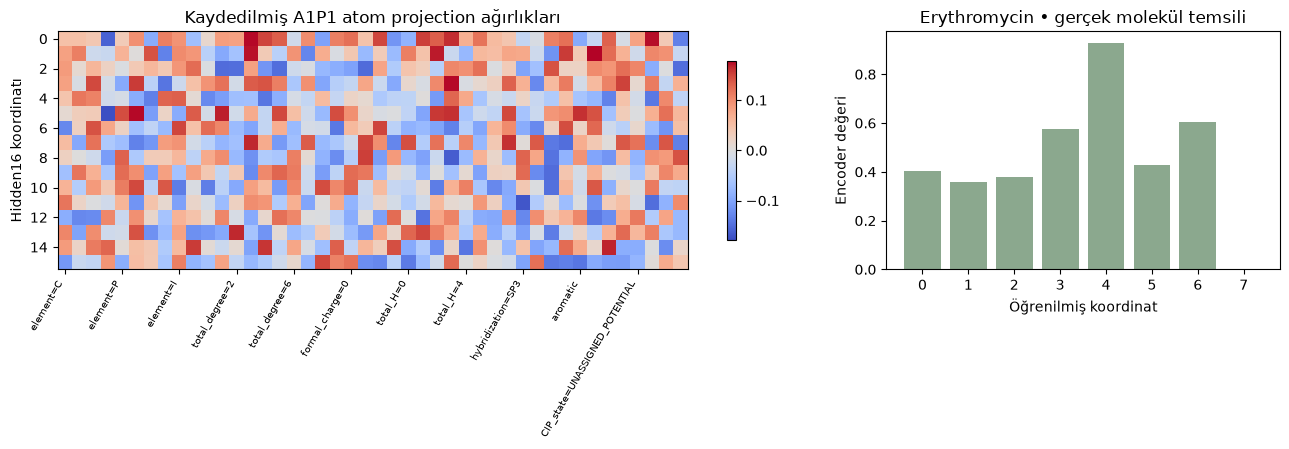

,job,model_NPZ,state_sha256,outer_epochs,input_drug
0,primary_o03_final_A1P1,models/WP10_factorial_training_v1/primary_o03_...,a3d586d08b2a48bf738ef9adc995bba252c1d56aeae7d6...,43,DB00199


In [7]:
example=json.loads((QA/'example_drug_inputs.json').read_text(encoding='utf-8'));display(pd.DataFrame([example]).T)
job=example['actual_model_jobs']['A1P1'];metadata=json.loads((MODEL/(job+'.json')).read_text(encoding='utf-8'));trained=restore(metadata);store=load_store()
with torch.no_grad():embedding=trained.molecular(store.make_batch([example['drug_id']]).batch)['molecular_h'][0].numpy()
weights=trained.molecular.projection.weight.detach().numpy();schema=json.loads((ROOT/'reports/qa/WP10/encoder_v1/feature_schema.json').read_text(encoding='utf-8'))
fig,axs=plt.subplots(1,2,figsize=(13,4.6),gridspec_kw={'width_ratios':[2,1]})
im=axs[0].imshow(weights,aspect='auto',cmap='coolwarm',vmin=-abs(weights).max(),vmax=abs(weights).max());plt.colorbar(im,ax=axs[0],shrink=.75)
indices=list(range(0,44,4));axs[0].set_xticks(indices,[schema['atom_columns'][i] for i in indices],rotation=60,ha='right',fontsize=7)
axs[0].set(title='Kaydedilmiş A1P1 atom projection ağırlıkları',ylabel='Hidden16 koordinatı')
axs[1].bar(range(8),embedding,color='#8ba88e');axs[1].set(title=example['name']+' • gerçek molekül temsili',xlabel='Öğrenilmiş koordinat',ylabel='Encoder değeri')
plt.tight_layout();plt.savefig(FIG/'06_actual_trained_model.png',dpi=160);plt.show()
display(pd.DataFrame([{'job':job,'model_NPZ':metadata['parameters_file'],'state_sha256':metadata['selected_state_sha256'],'outer_epochs':metadata['best_epoch'],'input_drug':example['drug_id']}]))

**Yorum:**Bu şekil gerçek outer modelin NPZ ağırlıklarından üretildi;temsili veri değildir. Örnek,sonuçlardan önce alfabetik ilk primary paired54 ID kuralıyla belirlenen Erythromycin'dir. Moleküler koordinatlar ve projection ağırlıkları tek başına önem/SHAP/nedensel açıklama değildir;burada yalnız gerçek eğitim ürününü gösterir. WP11 açıklanabilirlik çalışması yapılmadı.

## 7. Aynı gerçek ilacın dört modelde kayıt sıralaması

,model,rank,class_id,PT_name,observed_record_s,score_observed_record_proxy
0,A0P0,1,C0042963,Vomiting,1,0.929109
1,A0P0,2,C0011991,Diarrhoea,1,0.922717
2,A0P0,3,C0015230,Rash,1,0.919779
3,A0P0,4,C0040034,Thrombocytopenia,0,0.918922
4,A0P0,5,C0011603,Dermatitis,0,0.908135
5,A0P0,6,C0002792,Anaphylactic shock,1,0.902295
6,A0P0,7,C0020517,Hypersensitivity,1,0.897001
7,A0P0,8,C0033774,Pruritus,1,0.878981
8,A0P0,9,C0042109,Urticaria,1,0.862413
9,A0P0,10,C0018681,Headache,0,0.857242


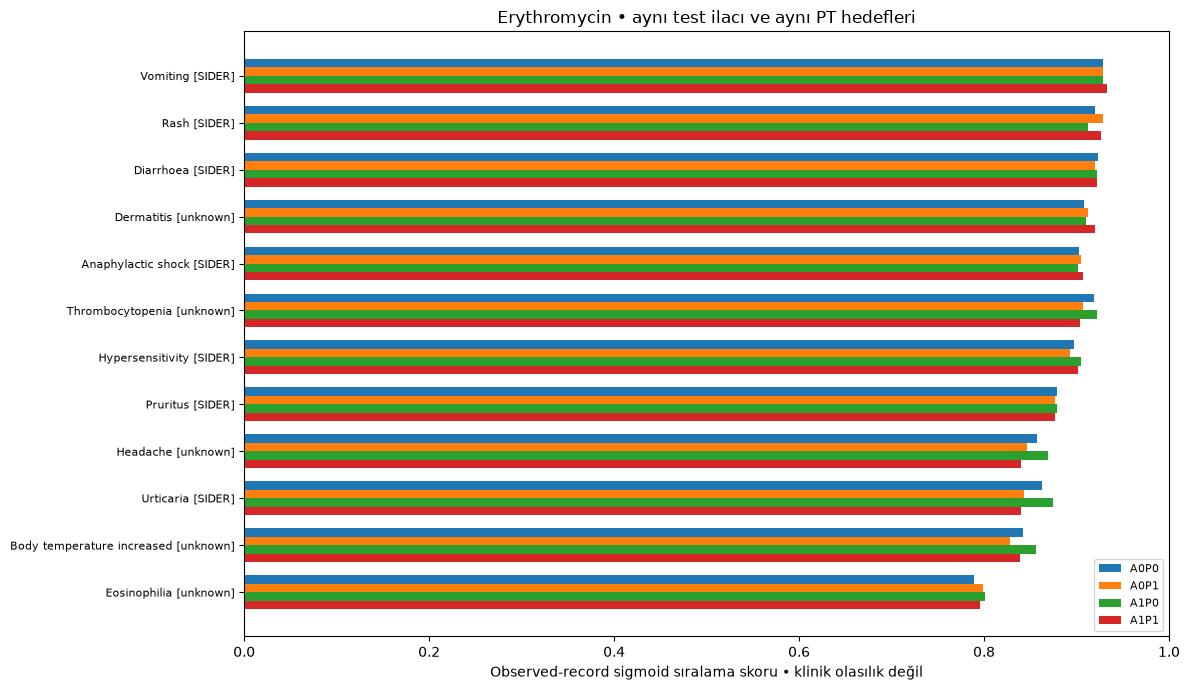

In [8]:
rank=pd.read_csv(QA/'example_drug_PT_ranking.csv')
display(rank[rank['rank'].le(10)][['model','rank','class_id','PT_name','observed_record_s','score_observed_record_proxy']])
names=rank[rank.model.eq('A1P1')].sort_values('rank').head(12).set_index('class_id')
fig,ax=plt.subplots(figsize=(12,7));yy=np.arange(len(names));width=.18
for j,name in enumerate(NAMES):
    rows=rank[rank.model.eq(name)].set_index('class_id').loc[names.index]
    ax.barh(yy+(j-1.5)*width,rows.score_observed_record_proxy,height=width,label=name)
ax.set_yticks(yy,[r.PT_name+(' [SIDER]' if r.observed_record_s else ' [unknown]') for r in names.itertuples()],fontsize=8)
ax.set(xlabel='Observed-record sigmoid sıralama skoru • klinik olasılık değil',xlim=(0,1),title=example['name']+' • aynı test ilacı ve aynı PT hedefleri');ax.invert_yaxis();ax.legend(fontsize=8)
plt.tight_layout();plt.savefig(FIG/'07_actual_drug_rankings.png',dpi=160);plt.show()

**Yorum:**Çizilen hedefler A1P1'in kaydedilmiş ilk12 PT sırasıdır;tablo her dört modelin kendi ilk10'unu da gösterir. Bütün skorlar aynı frozen test ilacının OOF CSV kaydından gelir. Unknown yüksek skorlar kesin yanlış pozitif veya klinik olay diye adlandırılmaz. Gösterim bir tedavi önerisi,klinik risk hesabı veya vaka doğrulaması değildir.

## 8. Testler,provenans ve durma noktası

In [9]:
text=(QA/'tests_actual_trainer.txt').read_text(encoding='utf-8-sig');print(text[-500:])
display(pd.read_csv(QA/'feature_fit_provenance.csv').head(4))
display(pd.DataFrame([json.loads((QA/'evaluation_complete.json').read_text(encoding='utf-8'))]).drop(columns=['semantics']))
display(pd.read_csv(QA/'fold_train_validation_test_scope.csv').head(8))

preflight.TrainingPreflight.test_04_train_proxy_single_outcome_and_test_validation_rejected) ... ok
test_05_optimizer_gradients_and_off_switches_real_trainer (test_wp10_training_preflight.TrainingPreflight.test_05_optimizer_gradients_and_off_switches_real_trainer) ... ok
test_06_finite_fit_failure_stays_NA (test_wp10_training_preflight.TrainingPreflight.test_06_finite_fit_failure_stays_NA) ... ok

----------------------------------------------------------------------
Ran 19 tests in 17.812s

OK



,job_key,context,model,classifier_fit_drug_ids,chemistry_scaler_fit_ids,protein_scaler_fit_accessions,preprocessing_refit,source,semantics
0,primary_o01_final_A0P0,primary_o01_final,A0P0,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""...",False,frozen WP08 transform_fit_sources_and_statisti...,Observed SIDER record ranking proxy; unknown N...
1,primary_o01_final_A0P1,primary_o01_final,A0P1,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""...",False,frozen WP08 transform_fit_sources_and_statisti...,Observed SIDER record ranking proxy; unknown N...
2,primary_o01_final_A1P0,primary_o01_final,A1P0,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""...",False,frozen WP08 transform_fit_sources_and_statisti...,Observed SIDER record ranking proxy; unknown N...
3,primary_o01_final_A1P1,primary_o01_final,A1P1,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""...",False,frozen WP08 transform_fit_sources_and_statisti...,Observed SIDER record ranking proxy; unknown N...


,seconds,bootstrap_replicates,no_refit,OOF_sha256,prior_files_verified,WP11,shuffled_PPI_experiments
0,90.742152,1000,True,787c6a911ff0c0b0a6f576458485f9a622be20e6341a3f...,2487,False,False


,job_key,context,model,train_graph_drugs,train_fit_drugs,validation_query_drugs,test_query_drugs,train_proteins,directed_PPI_columns,fitted_PT,declared_PT,heldout_drug_in_training,side_effect_edges
0,primary_o01_final_A0P0,primary_o01_final,A0P0,49,48,0,13,125,0,240,240,False,False
1,primary_o01_final_A0P1,primary_o01_final,A0P1,49,48,0,13,125,346,240,240,False,False
2,primary_o01_final_A1P0,primary_o01_final,A1P0,49,48,0,13,125,0,240,240,False,False
3,primary_o01_final_A1P1,primary_o01_final,A1P1,49,48,0,13,125,346,240,240,False,False
4,primary_o01_i01_A0P0,primary_o01_i01,A0P0,32,32,17,13,92,0,171,171,False,False
5,primary_o01_i01_A0P1,primary_o01_i01,A0P1,32,32,17,13,92,252,171,171,False,False
6,primary_o01_i01_A1P0,primary_o01_i01,A1P0,32,32,17,13,92,0,171,171,False,False
7,primary_o01_i01_A1P1,primary_o01_i01,A1P1,32,32,17,13,92,252,171,171,False,False


**Yorum:**Gerçek trainer testleri train-only PT/ID veproxy desteği,heldout label/value mutation,forward/gradient eşitliği,optimizer,girdi izolasyonu,NPZ skor veouter fit tekrar üretimi,ortak anahtarlar vefactorial aritmetiği kapsar. Kontrollü RAM test fitleri üretim modellerini değiştirmez;yeniden ayarlama değildir. Bütün kaynak/encoder/baseline/WP09 çıktıları hash ile korunur.

**WP10 gerçek eğitim ve değerlendirme tamamlandığında durulur. Sonuçlar observed-record proxy ve keşifseldir. Atom/PPI katkısının düşük veya belirsiz olması gizlenmez. WP11'e geçmek için kullanıcı onayı gerekir.**